In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

methods = ["ARMUL", "pERM"]
ns = [100, 200]
similaritys = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]
seeds = range(1,101)
records = []
for method in methods:
    for seed in seeds:
        for n in ns:
            for similarity in similaritys:

                file_path = f"/home/chen.yongzhuo/orange_gator_liang/yongzhuo/TransferSemi_5/CATE_pro_dim8/CATE_{n}_{similarity}/{method}_propensity_score_error{seed}.csv"

            
                df = pd.read_csv(file_path)
                value = df.mean().iloc[1]    # the number you want


                records.append({
                    "method": method,
                    "seed": seed,
                    "n": n,
                    "similarity": similarity,
                    "value": value
                })

# Convert to tidy DataFrame
results = pd.DataFrame(records)
print(results.head())


  method  seed    n  similarity    value
0  ARMUL     1  100         0.0  0.25616
1  ARMUL     1  100         0.1  0.25616
2  ARMUL     1  100         0.2  0.25616
3  ARMUL     1  100         0.3  0.25616
4  ARMUL     1  100         0.4  0.25616


In [16]:
results

,method,seed,n,similarity,value
0,ARMUL,1,100,0.0,0.256160
1,ARMUL,1,100,0.1,0.256160
2,ARMUL,1,100,0.2,0.256160
3,ARMUL,1,100,0.3,0.256160
4,ARMUL,1,100,0.4,0.256160
...,...,...,...,...,...
4395,pERM,100,200,0.6,0.249462
4396,pERM,100,200,0.7,0.251512
4397,pERM,100,200,0.8,0.252463
4398,pERM,100,200,0.9,0.248478


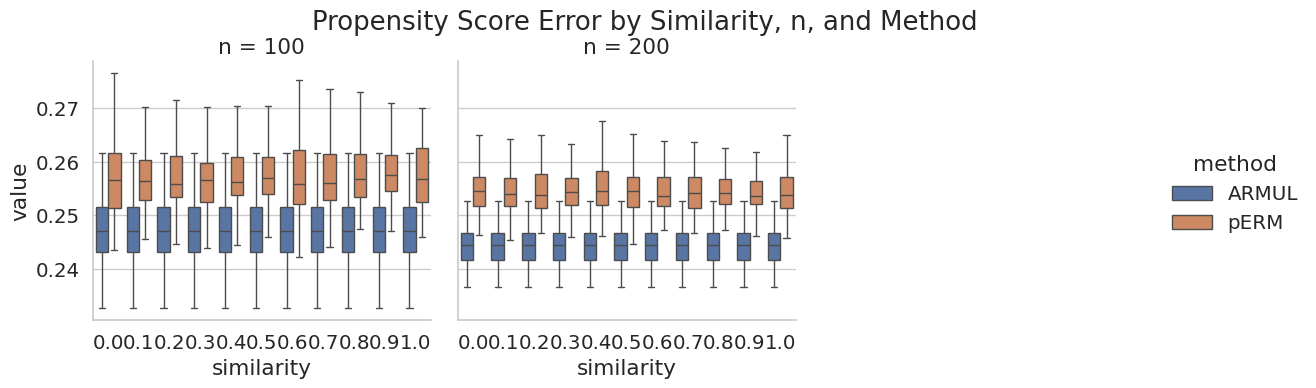

In [17]:
g = sns.catplot(
    data=results,
    x="similarity",
    y="value",
    hue="method",
    kind="box",
    col="n",
    col_wrap=3,
    height=4,
    aspect=1,
    showfliers=False
)

g.fig.subplots_adjust(top=0.85)
g.fig.suptitle("Propensity Score Error by Similarity, n, and Method")
plt.show()


In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from tqdm import tqdm

methods = ["ARMUL", "pERM"]
ns = [100, 200]
similaritys = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]
seeds = range(1, 101)

records = []
missing_files = []

for method in tqdm(methods):
    for seed in tqdm(seeds):
        for n in ns:
            for similarity in similaritys:

                file_path = (
                    f"/home/chen.yongzhuo/orange_gator_liang/yongzhuo/"
                    f"TransferSemi_5/CATE_test8/CATE_{n}_{similarity}/"
                    f"{method}_MSE_all_tasks_{seed}.csv"
                )

                if not os.path.exists(file_path):
                    missing_files.append(file_path)
                    continue

                df = pd.read_csv(file_path)

                # Expecting: task, MAE_mu1, MAE_mu0
                if method == "ARMUL":
                    # ARMUL has multiple tasks; average over tasks
                    mae_mu1 = df["MAE_mu1"].mean()
                    mae_mu0 = df["MAE_mu0"].mean()
                else:
                    mae_mu1 = df["MSE_mu1"].mean()
                    mae_mu0 = df["MSE_mu0"].mean()
                # Two entries per file
                records.append({
                    "method": method,
                    "seed": seed,
                    "n": n,
                    "similarity": similarity,
                    "mu": "mu1",
                    "value": mae_mu1,
                })

                records.append({
                    "method": method,
                    "seed": seed,
                    "n": n,
                    "similarity": similarity,
                    "mu": "mu0",
                    "value": mae_mu0,
                })

results = pd.DataFrame(records)
print(results.head())

print(f"Missing files: {len(missing_files)}")


100%|██████████| 2/2 [03:41<00:00, 110.93s/it]


  method  seed    n  similarity   mu     value
0  ARMUL     1  100         0.0  mu1  0.475228
1  ARMUL     1  100         0.0  mu0  0.487951
2  ARMUL     1  100         0.1  mu1  0.475566
3  ARMUL     1  100         0.1  mu0  0.487912
4  ARMUL     1  100         0.2  mu1  0.474992
Missing files: 0


/tmp/ipykernel_2847301/749345484.py:4: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.lineplot(


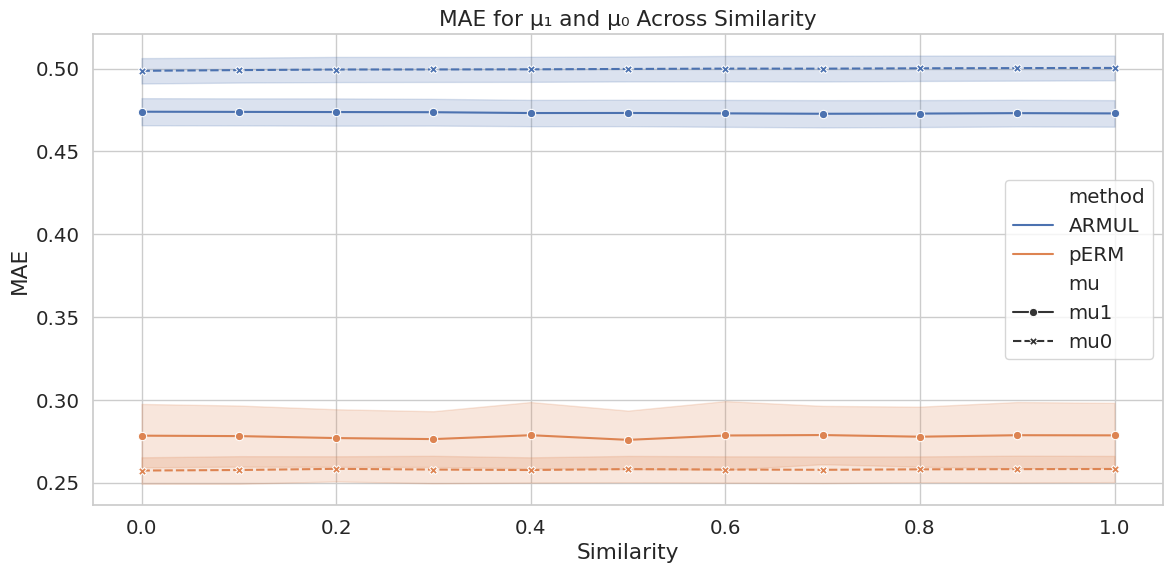

In [22]:
sns.set(style="whitegrid", font_scale=1.3)

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=results,
    x="similarity",
    y="value",
    hue="method",
    style="mu",
    markers=True,
    ci="sd"
)
plt.title("MAE for μ₁ and μ₀ Across Similarity")
plt.xlabel("Similarity")
plt.ylabel("MAE")
plt.tight_layout()
plt.show()


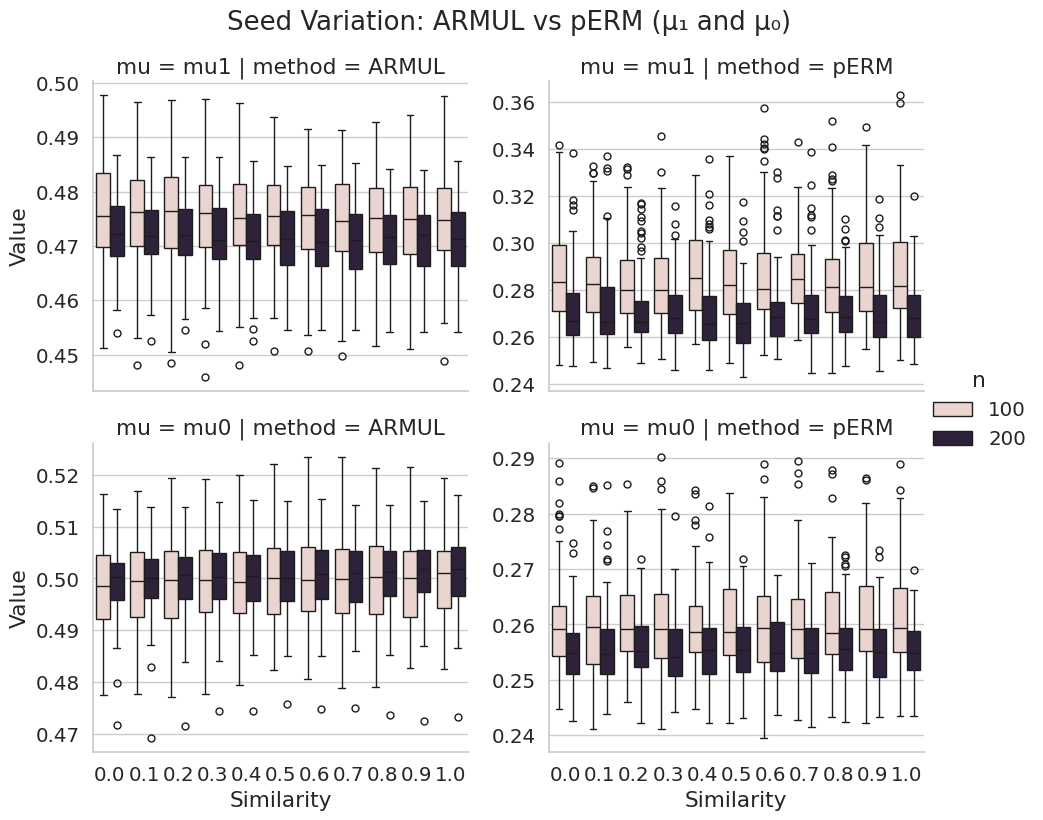

In [24]:
g = sns.catplot(
    data=results,
    x="similarity",
    y="value",
    hue="n",                # color difference for n=100 vs n=200
    col="method",           # side-by-side ARMUL vs pERM
    row="mu",               # μ₁ on top, μ₀ on bottom
    kind="box",
    height=4,
    aspect=1.2,
    sharey=False            # allow each μ panel its own y-axis
)

g.fig.suptitle("Seed Variation: ARMUL vs pERM (μ₁ and μ₀)", y=1.03)
g.set_axis_labels("Similarity", "Value")
plt.show()


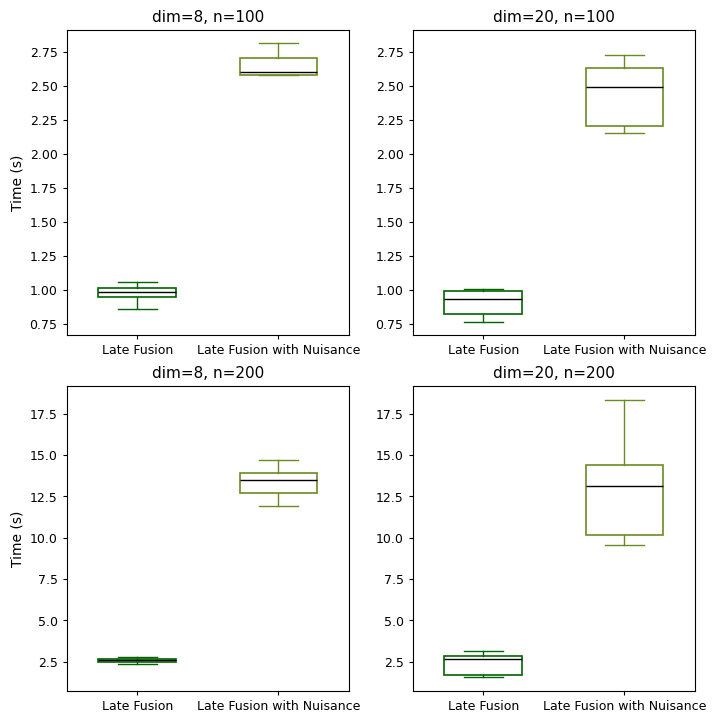

In [34]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

# ---------- R-like global style ----------
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "axes.linewidth": 0.8,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": 3,
    "ytick.major.size": 3,
})

BASE = Path("/home/chen.yongzhuo/orange_gator_liang/yongzhuo/TransferSemi_5")

dims = [8, 20]
ns = [100, 200]
simis = [round(x, 1) for x in np.linspace(0, 1, 11)]

rows = []
colors = {
    "Late Fusion": "darkgreen",
    "Late Fusion with Nuisance": "#698B22"
}

for dim in dims:
    root = BASE / f"time_6_dim_{dim}"
    for n in ns:
        for simi in simis:
            folder = root / f"_n_{n}_simi_{simi}"
            if not folder.exists():
                continue

            para_times, nonpar_times = [], []
            for f in folder.glob("time_data_seed_*.csv"):
                df = pd.read_csv(f)
                para_times.append(float(df["time_para_transfer"].iloc[0]))
                nonpar_times.append(float(df["time_nonpar_transfer"].iloc[0]))

            if len(para_times) == 0:
                continue

            rows.append({
                "dim": dim,
                "n": n,
                "simi": simi,
                "para": float(np.mean(para_times)),
                "nonpar": float(np.mean(nonpar_times)),
            })

wide = pd.DataFrame(rows)

long = wide.melt(
    id_vars=["dim", "n", "simi"],
    value_vars=["para", "nonpar"],
    var_name="method",
    value_name="time",
)
long["method"] = long["method"].map({
    "para": "Late Fusion",
    "nonpar": "Late Fusion with Nuisance"
})

fig, axes = plt.subplots(len(ns), len(dims), figsize=(7.2, 7.2), sharey=False)
axes = np.array(axes).reshape(len(ns), len(dims))

methods = ["Late Fusion", "Late Fusion with Nuisance"]

for j, n in enumerate(ns):
    for i, dim in enumerate(dims):
        ax = axes[j, i]
        sub = long[(long["dim"] == dim) & (long["n"] == n)]

        data = [sub[sub["method"] == m]["time"].to_numpy() for m in methods]

        # --- R-like boxplot styling ---
        bp = ax.boxplot(
            data,
            labels=methods,
            patch_artist=True,
            showfliers=False,
            widths=0.55,  # R-like
            medianprops=dict(color="black", linewidth=1.0),
            whiskerprops=dict(color="black", linewidth=0.8),
            capprops=dict(color="black", linewidth=0.8),
            boxprops=dict(edgecolor="black", linewidth=0.8),
        )

        # Option A (more R-like): white fill + colored border by method
        # Uncomment this block if you want the classic R look.
        for box, m in zip(bp["boxes"], methods):
            box.set_facecolor("white")
            box.set_edgecolor(colors[m])
            box.set_linewidth(1.2)

        # Also color whiskers/caps to match the box border (optional, R-ish)
        # Each box has 2 whiskers + 2 caps in order
        for k, m in enumerate(methods):
            for obj in (bp["whiskers"][2*k], bp["whiskers"][2*k+1],
                        bp["caps"][2*k], bp["caps"][2*k+1]):
                obj.set_color(colors[m])
                obj.set_linewidth(1.0)

        # Keep median black like base R
        # (already set via medianprops)

        ax.set_title(f"dim={dim}, n={n}")
        if i == 0:
            ax.set_ylabel("Time (s)")

        # R-like axes: no grid, show full box
        ax.grid(False)
        for spine in ax.spines.values():
            spine.set_visible(True)

# share y-axis within each row (same n)
for j in range(len(ns)):
    ymins, ymaxs = [], []
    for i in range(len(dims)):
        ymin, ymax = axes[j, i].get_ylim()
        ymins.append(ymin)
        ymaxs.append(ymax)
    ymin, ymax = min(ymins), max(ymaxs)
    for i in range(len(dims)):
        axes[j, i].set_ylim(ymin, ymax)

fig.tight_layout(pad=0.6)
plt.show()
fig.savefig("/blue/sai.zhang/chen.yongzhuo/TransferSemi_5/runtime_boxplots_Rstyle.pdf",
            bbox_inches="tight")


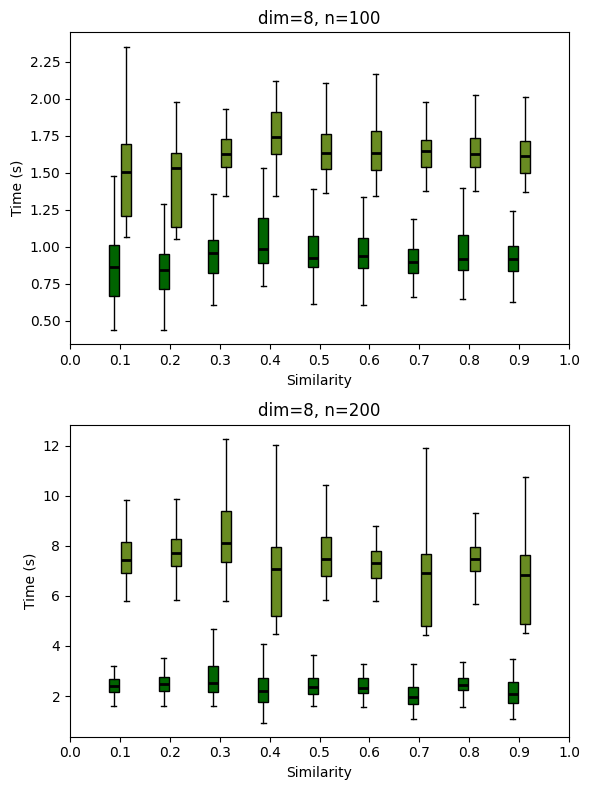

In [28]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

BASE = Path("/home/chen.yongzhuo/orange_gator_liang/yongzhuo/TransferSemi_5")

dims = [8]
ns = [100, 200]
simis = [round(x, 1) for x in np.linspace(0, 1, 11)]

rows = []
colors = {
    "Late Fusion": "darkgreen",
    "Late Fusion with Nuisance": "#698B22"
}

# ⭐ collect raw seed-level data (NO averaging)
for dim in dims:
    root = BASE / f"time_5_dim_{dim}"
    for n in ns:
        for simi in simis:
            folder = root / f"_n_{n}_simi_{simi}"
            if not folder.exists():
                continue

            for f in folder.glob("time_data_seed_*.csv"):
                df = pd.read_csv(f)
                rows.append({
                    "dim": dim,
                    "n": n,
                    "simi": simi,
                    "Late Fusion": float(df["time_para_transfer"].iloc[0]),
                    "Late Fusion with Nuisance":
                        float(df["time_nonpar_transfer"].iloc[0]),
                })

df = pd.DataFrame(rows)

# reshape
long = df.melt(
    id_vars=["dim", "n", "simi"],
    var_name="method",
    value_name="time"
)

# -------- plotting --------
fig, axes = plt.subplots(len(ns), len(dims), figsize=(6, 8), sharey=False)
axes = np.array(axes).reshape(len(ns), len(dims))

methods = ["Late Fusion", "Late Fusion with Nuisance"]

for j, n in enumerate(ns):
    for i, dim in enumerate(dims):
        ax = axes[j, i]
        sub = long[(long["dim"] == dim) & (long["n"] == n)]

        positions = []
        data = []

        for k, simi in enumerate(simis):
            for m_idx, m in enumerate(methods):
                tmp = sub[(sub["simi"] == simi) & (sub["method"] == m)]["time"]
                if len(tmp) == 0:
                    continue

                # slight horizontal offset for two methods
                positions.append(k + 1 + (m_idx - 0.5) * 0.25)
                data.append(tmp.values)

        bp = ax.boxplot(
            data,
            positions=positions,
            widths=0.2,
            patch_artist=True,
            showfliers=False,
            medianprops=dict(color="black", linewidth=2),
            whiskerprops=dict(color="black"),
            capprops=dict(color="black"),
            boxprops=dict(edgecolor="black"),
        )

        # color boxes alternating by method
        for idx, patch in enumerate(bp["boxes"]):
            patch.set_facecolor(colors[methods[idx % 2]])

        ax.set_xticks(range(1, len(simis) + 1))
        ax.set_xticklabels(simis)
        ax.set_xlabel("Similarity")
        ax.set_ylabel("Time (s)")
        ax.set_title(f"dim={dim}, n={n}")

plt.tight_layout()
plt.show()

fig.savefig(
    "/blue/sai.zhang/chen.yongzhuo/TransferSemi_5/runtime_vs_similarity_boxplot.pdf",
    bbox_inches="tight"
)
